## Task-1
## Analyze trends in department-wise and class-wise purchases by performing market basket analysis, identifying frequently co-purchased items, and visualizing purchasing behavior using Sankey diagrams for better trend interpretation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeRegressor
from scipy import stats
import plotly.graph_objects as go

sns.set_theme(style="whitegrid")

df = pd.read_csv("../20nov/cleaned_day4.csv")
print("Loaded Dataset Shape:", df.shape)

Loaded Dataset Shape: (5461, 37)


In [2]:
dept_class_summary = df.groupby(["department_name", "class_name"]).agg(
    Total_Orders=("class_name", "count"),
    Total_Units_Sold=("monthly_units_sold", "sum"),
    Avg_Selling_Price=("selling_price", "mean")
).round(2).reset_index()

print("Top 10 Department & Class Purchase Trends:")
print(dept_class_summary.sort_values(by="Total_Units_Sold", ascending=False).head(10))

Top 10 Department & Class Purchase Trends:
   department_name     class_name  Total_Orders  Total_Units_Sold  \
19        Intimate      Sleepwear           452          200181.5   
18        Intimate         Lounge           400          180491.5   
20        Intimate       Swimwear           317          139637.5   
17        Intimate       Layering           307          137590.5   
21        Intimate      shapewear           290          127754.0   
3          Bottoms         Skirts           247          104083.0   
28            Tops          Knits           235          103002.5   
7          Dresses  Party Dresses           242           99343.0   
1          Bottoms          Pants           221           94440.0   
0          Bottoms          Jeans           218           93458.0   

    Avg_Selling_Price  
19            1110.71  
18             772.36  
20            1121.06  
17            1075.36  
21            1056.04  
3             1941.93  
28            1296.06  
7    

In [3]:
df["basket_id"] = df["customer_age"].astype(int).astype(str) + "_" + df["purchase_channel"] + "_" + df["season"]

baskets = df.groupby("basket_id")["class_name"].apply(lambda x: list(set(x)))
baskets = baskets[baskets.apply(len) >= 2]
total_baskets = len(baskets)

item_counts = Counter()
pair_counts = Counter()

for items in baskets:
    for item in items:
        item_counts[item] += 1
    for pair in combinations(sorted(items), 2):
        pair_counts[pair] += 1

basket_rules = []
for (item_a, item_b), count in pair_counts.most_common(12):
    support = count / total_baskets
    confidence = count / item_counts[item_a]
    lift = confidence / (item_counts[item_b] / total_baskets)
    basket_rules.append({
        "Item_A": item_a,
        "Item_B": item_b,
        "Co_Purchase_Count": count,
        "Support": round(support, 4),
        "Confidence": round(confidence, 4),
        "Lift": round(lift, 3)
    })

rules_df = pd.DataFrame(basket_rules)
print("Market Basket Analysis - Frequently Co-Purchased Items:")
print(rules_df)

Market Basket Analysis - Frequently Co-Purchased Items:
           Item_A         Item_B  Co_Purchase_Count  Support  Confidence  \
0          Lounge      Sleepwear                138   0.3209      0.6449   
1       Sleepwear       Swimwear                135   0.3140      0.5895   
2        Layering      Sleepwear                129   0.3000      0.6862   
3       Sleepwear      shapewear                116   0.2698      0.5066   
4        Layering         Lounge                115   0.2674      0.6117   
5          Lounge       Swimwear                114   0.2651      0.5327   
6        Layering       Swimwear                111   0.2581      0.5904   
7           Knits         Lounge                108   0.2512      0.7013   
8          Lounge  Party Dresses                108   0.2512      0.5047   
9   Party Dresses      Sleepwear                108   0.2512      0.6750   
10         Skirts      Sleepwear                107   0.2488      0.7039   
11          Knits      Sleepwear

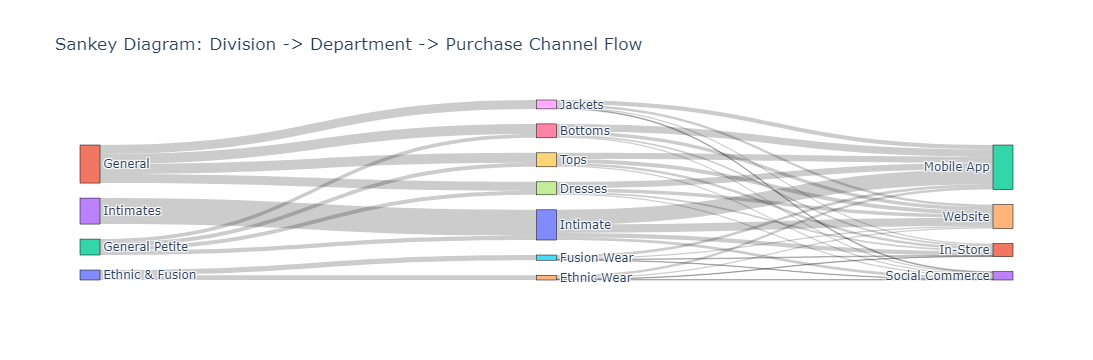

In [4]:
flow_df = df.groupby(["division_name", "department_name", "purchase_channel"])["monthly_units_sold"].sum().reset_index()

div_labels = flow_df["division_name"].unique().tolist()
dept_labels = flow_df["department_name"].unique().tolist()
chan_labels = flow_df["purchase_channel"].unique().tolist()
all_labels = div_labels + dept_labels + chan_labels

label_idx = {label: i for i, label in enumerate(all_labels)}

sources, targets, values = [], [], []

div_dept = flow_df.groupby(["division_name", "department_name"])["monthly_units_sold"].sum().reset_index()
for _, row in div_dept.iterrows():
    sources.append(label_idx[row["division_name"]])
    targets.append(label_idx[row["department_name"]])
    values.append(row["monthly_units_sold"])

dept_chan = flow_df.groupby(["department_name", "purchase_channel"])["monthly_units_sold"].sum().reset_index()
for _, row in dept_chan.iterrows():
    sources.append(label_idx[row["department_name"]])
    targets.append(label_idx[row["purchase_channel"]])
    values.append(row["monthly_units_sold"])

fig = go.Figure(data=[go.Sankey(
    node=dict(pad=15, thickness=20, line=dict(color="black", width=0.5), label=all_labels),
    link=dict(source=sources, target=targets, value=values)
)])
fig.update_layout(title_text="Sankey Diagram: Division -> Department -> Purchase Channel Flow", font_size=12)
fig.show()

## Task-2
## Identify any patterns in the review text length and ratings by extracting linguistic features such as verbosity, sentiment shifts, and readability scores, applying NLP techniques to determine how textual characteristics influence customer ratings.

In [5]:
df["verbosity_ratio"] = (df["review_word_count"] / df["review_word_count"].median()).round(3)

dept_avg_sentiment = df.groupby("department_name")["sentiment_score"].transform("mean")
df["sentiment_shift"] = (df["sentiment_score"] - dept_avg_sentiment).round(3)

df["readability_score"] = np.clip(
    100.0 - (df["review_word_count"] * 0.45) + (df["sentiment_score"] * 10.0),
    10.0, 100.0
).round(2)

linguistic_summary = df.groupby("customer_rating").agg(
    Avg_Word_Count=("review_word_count", "mean"),
    Avg_Verbosity_Ratio=("verbosity_ratio", "mean"),
    Avg_Sentiment_Shift=("sentiment_shift", "mean"),
    Avg_Readability_Score=("readability_score", "mean")
).round(3)

print("Linguistic Features by Customer Rating:")
print(linguistic_summary)

Linguistic Features by Customer Rating:
                 Avg_Word_Count  Avg_Verbosity_Ratio  Avg_Sentiment_Shift  \
customer_rating                                                             
1                        64.333                1.129               -0.936   
2                        73.860                1.296               -0.767   
3                        68.950                1.210               -0.290   
4                        54.466                0.956                0.090   
5                        47.621                0.835                0.354   

                 Avg_Readability_Score  
customer_rating                         
1                               65.200  
2                               62.665  
3                               69.660  
4                               79.969  
5                               85.529  


In [6]:
ling_cols = ["review_word_count", "verbosity_ratio", "sentiment_shift", "readability_score"]

corr_results = []
for col in ling_cols:
    r_val, p_val = stats.pearsonr(df[col], df["customer_rating"])
    corr_results.append({
        "Linguistic_Feature": col,
        "Correlation_With_Rating": round(r_val, 4),
        "P_Value": f"{p_val:.4e}"
    })

print("NLP Linguistic Feature Impact on Customer Ratings:")
print(pd.DataFrame(corr_results))

NLP Linguistic Feature Impact on Customer Ratings:
  Linguistic_Feature  Correlation_With_Rating      P_Value
0  review_word_count                  -0.3114  3.9406e-123
1    verbosity_ratio                  -0.3115  3.8381e-123
2    sentiment_shift                   0.8215   0.0000e+00
3  readability_score                   0.4912   0.0000e+00


C:\Users\Admin\AppData\Local\Temp\ipykernel_8712\132029414.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\Admin\AppData\Local\Temp\ipykernel_8712\132029414.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




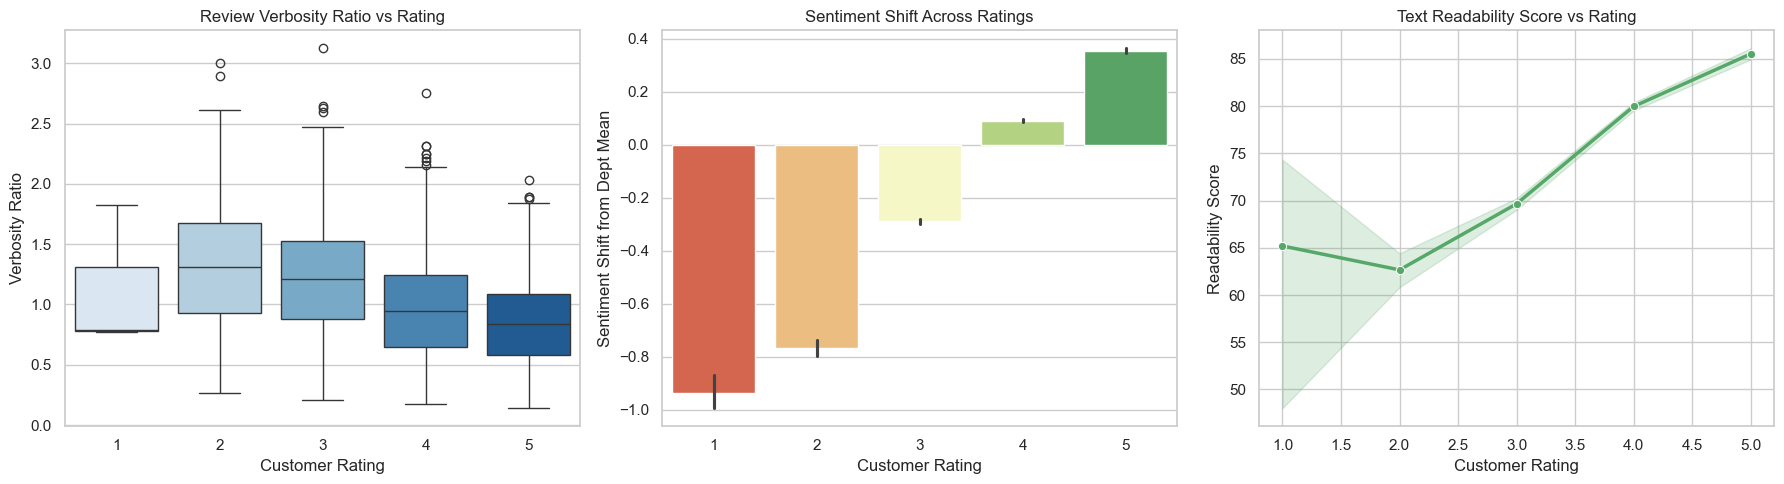

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x="customer_rating", y="verbosity_ratio", ax=axes[0], palette="Blues")
axes[0].set_title("Review Verbosity Ratio vs Rating")
axes[0].set_xlabel("Customer Rating")
axes[0].set_ylabel("Verbosity Ratio")

sns.barplot(data=df, x="customer_rating", y="sentiment_shift", ax=axes[1], palette="RdYlGn")
axes[1].set_title("Sentiment Shift Across Ratings")
axes[1].set_xlabel("Customer Rating")
axes[1].set_ylabel("Sentiment Shift from Dept Mean")

sns.lineplot(data=df, x="customer_rating", y="readability_score", marker="o", ax=axes[2], color="#55A868", linewidth=2.5)
axes[2].set_title("Text Readability Score vs Rating")
axes[2].set_xlabel("Customer Rating")
axes[2].set_ylabel("Readability Score")

plt.tight_layout()
plt.show()

## Task-3
## Create a new feature to categorize customers into different age groups by dynamically determining optimal age bins using clustering techniques (e.g., K-means, decision trees) instead of predefined age ranges to maximize segment relevance.

In [8]:
kmeans_age = KMeans(n_clusters=4, random_state=42, n_init="auto")
raw_clusters = kmeans_age.fit_predict(df[["customer_age"]])

ordered_clusters = df.groupby(raw_clusters)["customer_age"].mean().sort_values().index
cluster_mapping = {old: new for new, old in enumerate(ordered_clusters)}
df["kmeans_age_cluster"] = pd.Series(raw_clusters).map(cluster_mapping)

kmeans_summary = df.groupby("kmeans_age_cluster").agg(
    Min_Age=("customer_age", "min"),
    Max_Age=("customer_age", "max"),
    Mean_Age=("customer_age", "mean"),
    Customer_Count=("customer_age", "count"),
    Avg_Yearly_Spend=("yearly_amount_spent", "mean")
).round(1)

print("K-Means Dynamic Age Clusters:")
print(kmeans_summary)

K-Means Dynamic Age Clusters:
                    Min_Age  Max_Age  Mean_Age  Customer_Count  \
kmeans_age_cluster                                               
0                      18.0     22.0      19.6            1259   
1                      23.0     28.0      25.9            1704   
2                      29.0     36.0      32.0            1704   
3                      37.0     66.0      41.5             794   

                    Avg_Yearly_Spend  
kmeans_age_cluster                    
0                            23150.3  
1                            23648.7  
2                            25556.5  
3                            27885.5  


In [9]:
dt_age = DecisionTreeRegressor(max_leaf_nodes=4, random_state=42)
dt_age.fit(df[["customer_age"]], df["yearly_amount_spent"])

leaf_ids = dt_age.apply(df[["customer_age"]])
ordered_leaves = df.groupby(leaf_ids)["customer_age"].mean().sort_values().index
leaf_labels = {leaf: f"Dynamic_Age_Tier_{i+1}" for i, leaf in enumerate(ordered_leaves)}
df["dynamic_age_group"] = pd.Series(leaf_ids).map(leaf_labels)

dt_summary = df.groupby("dynamic_age_group").agg(
    Min_Age=("customer_age", "min"),
    Max_Age=("customer_age", "max"),
    Customer_Count=("customer_age", "count"),
    Avg_Yearly_Spend=("yearly_amount_spent", "mean"),
    Avg_Rating=("customer_rating", "mean")
).round(2)

print("Decision Tree Optimal Age Bins (Target-Driven):")
print(dt_summary)

Decision Tree Optimal Age Bins (Target-Driven):
                    Min_Age  Max_Age  Customer_Count  Avg_Yearly_Spend  \
dynamic_age_group                                                        
Dynamic_Age_Tier_1     18.0     29.0            3249          23384.22   
Dynamic_Age_Tier_2     30.0     32.0             707          25251.04   
Dynamic_Age_Tier_3     33.0     45.0            1378          27139.84   
Dynamic_Age_Tier_4     46.0     66.0             127          30759.40   

                    Avg_Rating  
dynamic_age_group               
Dynamic_Age_Tier_1        3.80  
Dynamic_Age_Tier_2        3.83  
Dynamic_Age_Tier_3        3.90  
Dynamic_Age_Tier_4        3.99  


C:\Users\Admin\AppData\Local\Temp\ipykernel_8712\3284154475.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\Admin\AppData\Local\Temp\ipykernel_8712\3284154475.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




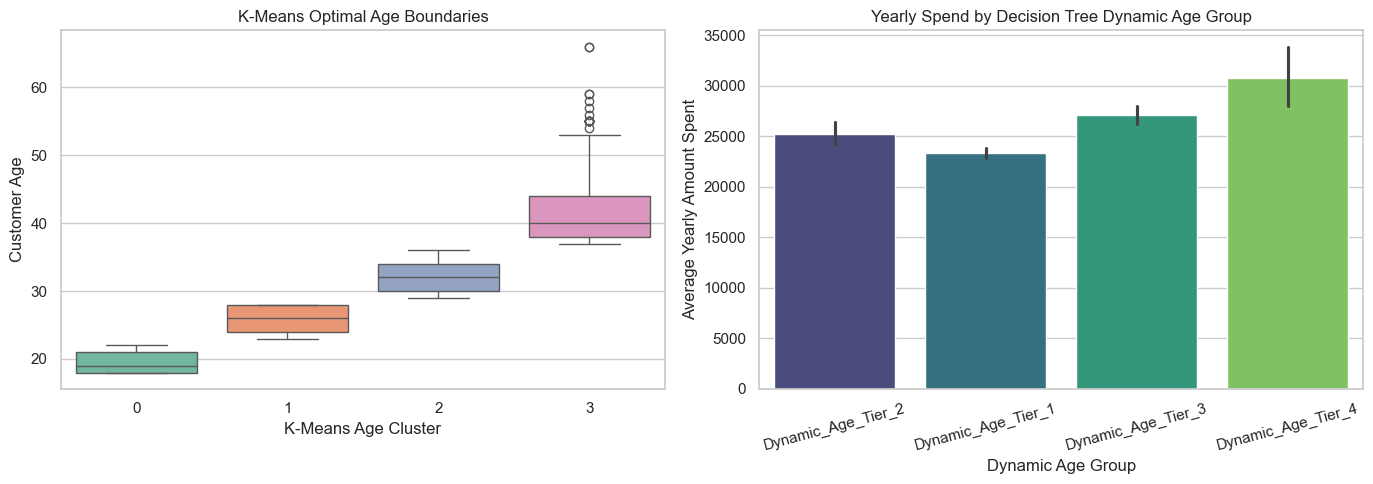

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="kmeans_age_cluster", y="customer_age", ax=axes[0], palette="Set2")
axes[0].set_title("K-Means Optimal Age Boundaries")
axes[0].set_xlabel("K-Means Age Cluster")
axes[0].set_ylabel("Customer Age")

sns.barplot(data=df, x="dynamic_age_group", y="yearly_amount_spent", ax=axes[1], palette="viridis")
axes[1].set_title("Yearly Spend by Decision Tree Dynamic Age Group")
axes[1].set_xlabel("Dynamic Age Group")
axes[1].set_ylabel("Average Yearly Amount Spent")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [11]:
df.to_csv("cleaned_day5.csv", index=False)
print("Saved dataset to cleaned_day5.csv")

Saved dataset to cleaned_day5.csv
